# Image geometry and foreground segmentation

Jim Lo and Ta-Chun Tai

In [ ]:
# Run with OpenCV, NumPy, matplotlib and IPython installed.

In [ ]:
import glob
import json
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

ROOT = Path.cwd() / "data"
IMG_EXT = {".jpg", ".png"}


def images_under(folder):
    return sorted([p for p in Path(folder).rglob("*") if p.suffix.lower() in IMG_EXT])


def read_bgr(path):
    im = cv2.imread(str(path))
    if im is None:
        raise FileNotFoundError(path)
    return im


def show(title, im, cmap=None, figsize=(12, 7)):
    plt.figure(figsize=figsize)
    plt.title(title)
    if im.ndim == 3:
        plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(im, cmap=cmap or "gray")
    plt.axis("off")
    plt.show()

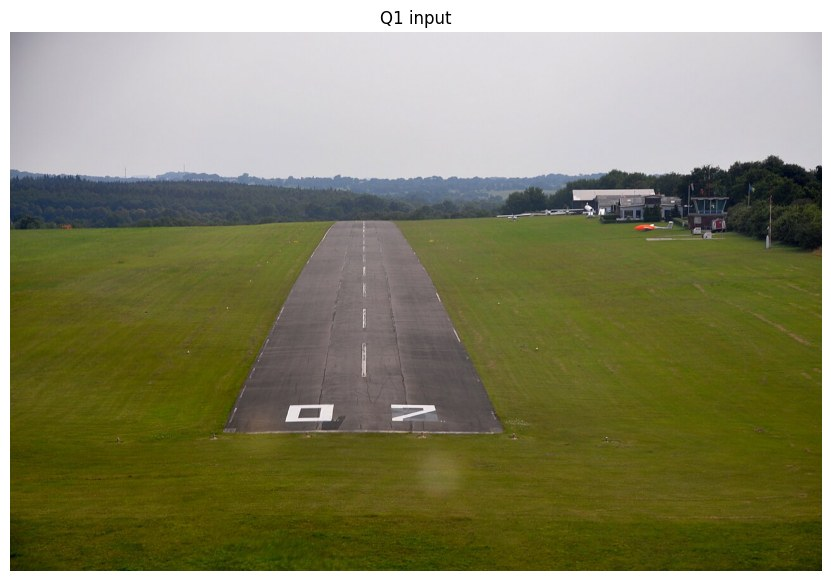

In [ ]:
im = read_bgr(ROOT / "Q1" / "Runway.jpg")
h, w = im.shape[:2]
show("Q1 input", im)
print("image shape", im.shape)

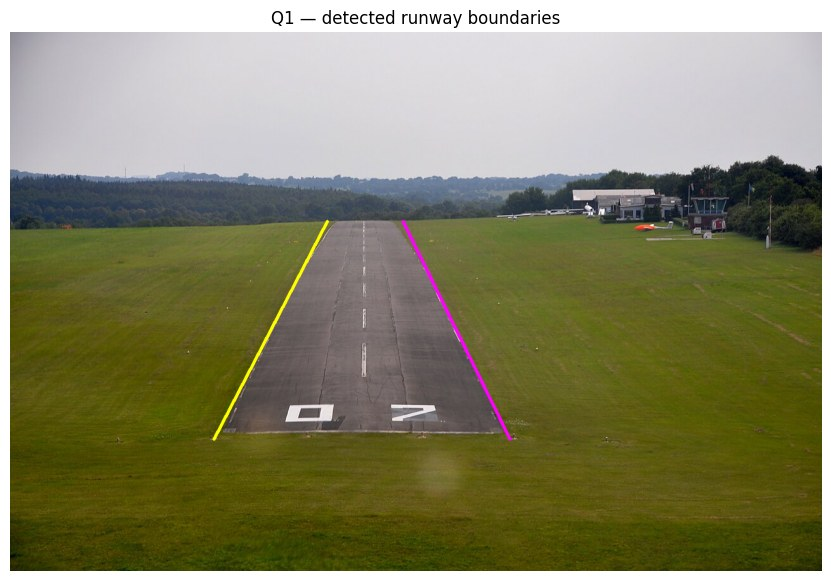

left support segments 9 slope -0.522
right support segments 4 slope 0.491


In [ ]:
im = read_bgr(ROOT / "Q1" / "Runway.jpg")
h, w = im.shape[:2]

# Enhance pavement/grass contrast and detect line segments.
b, g, r = cv2.split(im.astype(np.float32))
exg = 2 * g - r - b
exg8 = cv2.normalize(exg, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
edges = cv2.Canny(cv2.GaussianBlur(exg8, (5, 5), 0), 20, 70)
raw = cv2.HoughLinesP(edges, 1, np.pi / 180, 20, minLineLength=35, maxLineGap=40)
segments = (
    []
    if raw is None
    else [tuple(map(int, line)) for line in np.asarray(raw).reshape(-1, 4)]
)

# Keep plausible left/right boundary segments.
candidates = {"left": [], "right": []}
for s in segments:
    x1, y1, x2, y2 = s
    if abs(y2 - y1) < 35:
        continue
    slope = (x2 - x1) / (y2 - y1)
    if not 0.2 < abs(slope) < 1.5:
        continue
    mid_x = (x1 + x2) / 2
    if slope < 0 and mid_x < w / 2:
        candidates["left"].append(s)
    if slope > 0 and mid_x > w / 2:
        candidates["right"].append(s)

# Fit one line from supporting segments on each side.
fits = {}
for side in candidates:
    if not candidates[side]:
        raise RuntimeError("No " + side + " boundary segment")
    seed = max(candidates[side], key=lambda s: np.hypot(s[2] - s[0], s[3] - s[1]))
    x1, y1, x2, y2 = seed
    m = (x2 - x1) / (y2 - y1)
    c = x1 - m * y1
    aligned = [
        s
        for s in candidates[side]
        if abs((s[0] + s[2]) / 2 - (m * (s[1] + s[3]) / 2 + c)) < 12
    ]
    ys = np.array([y for s in aligned for y in (s[1], s[3])])
    xs = np.array([x for s in aligned for x in (s[0], s[2])])
    m, c = np.polyfit(ys, xs, 1)
    fits[side] = (m, c, int(ys.min()), int(ys.max()))
    print(side, "support segments", len(aligned), "slope", round(m, 3))

# Overlay exactly two fitted boundaries on the input image.
y_top = min(fits[side][2] for side in fits)
y_bottom = max(fits[side][3] for side in fits)
result = im.copy()
for side, color in [("left", (0, 255, 255)), ("right", (255, 0, 255))]:
    m, c, _, _ = fits[side]
    cv2.line(
        result,
        (round(m * y_top + c), y_top),
        (round(m * y_bottom + c), y_bottom),
        color,
        4,
    )
show("Q1 — detected runway boundaries", result)

### Q1 — Runway boundary detection

- Read the runway image directly in the Q1 cell so it does not depend on variables changed by other questions.
- Compute an excess-green contrast image, smooth it, and apply Canny edge detection.
- Use probabilistic Hough detection to obtain candidate line segments. Keep long, diagonal segments with the expected left/right slopes, then fit one supported line on each side.
- Draw exactly two computed lines on the original image. They follow the pavement–grass boundaries; small endpoint offsets may remain.

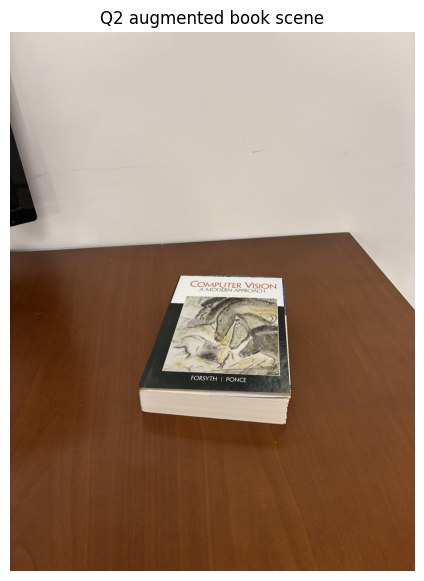

Scene/source/replacement shapes: (5712, 4284, 3) (2527, 1729, 3) (1000, 792, 3)
Good matches: 158 RANSAC inliers: 36 ratio: 0.228
Detected cover corners: [[1791, 2581], [2877, 2606], [2964, 3829], [1348, 3768]]


In [ ]:
scene = read_bgr(ROOT / "Q2" / "Scene.png")
source = read_bgr(ROOT / "Q2" / "Source_Screen.png")
repl = read_bgr(ROOT / "Q2" / "replacement_screen.jpg")


def shrink(im, maxdim):
    scale = min(1.0, maxdim / max(im.shape[:2]))
    return cv2.resize(im, None, fx=scale, fy=scale), scale


# Match SIFT features and estimate a RANSAC homography.
scene_s, ss = shrink(scene, 1800)
source_s, ts = shrink(source, 1200)
sift = cv2.SIFT_create(nfeatures=6000)
k1, d1 = sift.detectAndCompute(cv2.cvtColor(source_s, cv2.COLOR_BGR2GRAY), None)
k2, d2 = sift.detectAndCompute(cv2.cvtColor(scene_s, cv2.COLOR_BGR2GRAY), None)
pairs = cv2.BFMatcher().knnMatch(d1, d2, k=2)
good = [m for m, n in pairs if m.distance < 0.72 * n.distance]
assert len(good) >= 12, f"Only {len(good)} reliable matches"
p1 = np.float32([k1[m.queryIdx].pt for m in good])
p2 = np.float32([k2[m.trainIdx].pt for m in good])
Hs, inliers = cv2.findHomography(p1, p2, cv2.RANSAC, 4.0)
assert Hs is not None and int(inliers.sum()) >= 10
# Project the original cover corners into the scene.
H = np.diag([1 / ss, 1 / ss, 1]) @ Hs @ np.diag([ts, ts, 1])
sh, sw = source.shape[:2]
hh, ww = scene.shape[:2]
corners = np.float32([[0, 0], [sw - 1, 0], [sw - 1, sh - 1], [0, sh - 1]]).reshape(
    -1, 1, 2
)
quad = cv2.perspectiveTransform(corners, H).reshape(-1, 2)
assert np.all(np.isfinite(quad)) and cv2.contourArea(quad.astype(np.float32)) > 1000
# Warp and composite replacement artwork inside the detected cover.
replacement = cv2.resize(repl, (sw, sh), interpolation=cv2.INTER_CUBIC)
warped = cv2.warpPerspective(replacement, H, (ww, hh))
mask = np.zeros((hh, ww), np.uint8)
cv2.fillConvexPoly(mask, np.round(quad).astype(np.int32), 255)
mask = cv2.erode(mask, np.ones((3, 3), np.uint8), iterations=1)
augmented = np.where(mask[:, :, None] > 0, warped, scene)
# Check match counts and display the augmented scene.
print("Scene/source/replacement shapes:", scene.shape, source.shape, repl.shape)
print(
    "Good matches:",
    len(good),
    "RANSAC inliers:",
    int(inliers.sum()),
    "ratio:",
    round(float(inliers.mean()), 3),
)
print("Detected cover corners:", np.round(quad).astype(int).tolist())
show(
    "Q2 augmented book scene",
    cv2.resize(augmented, None, fx=min(1, 1400 / ww), fy=min(1, 1400 / ww)),
)

### Q2 — Book cover replacement

- Load the scene, original cover, and replacement cover; resize copies for efficient SIFT matching.
- Match descriptors from the original cover to the scene, filter ambiguous matches, and estimate a homography with RANSAC.
- Project the source-cover corners into the scene to locate the physical front cover automatically.
- Resize and perspective-warp the replacement artwork into that quadrilateral, then composite only inside the cover mask. The rest of the scene is taken from the original photo.
- Check the displayed augmented image and the reported match/inlier counts and projected corners.

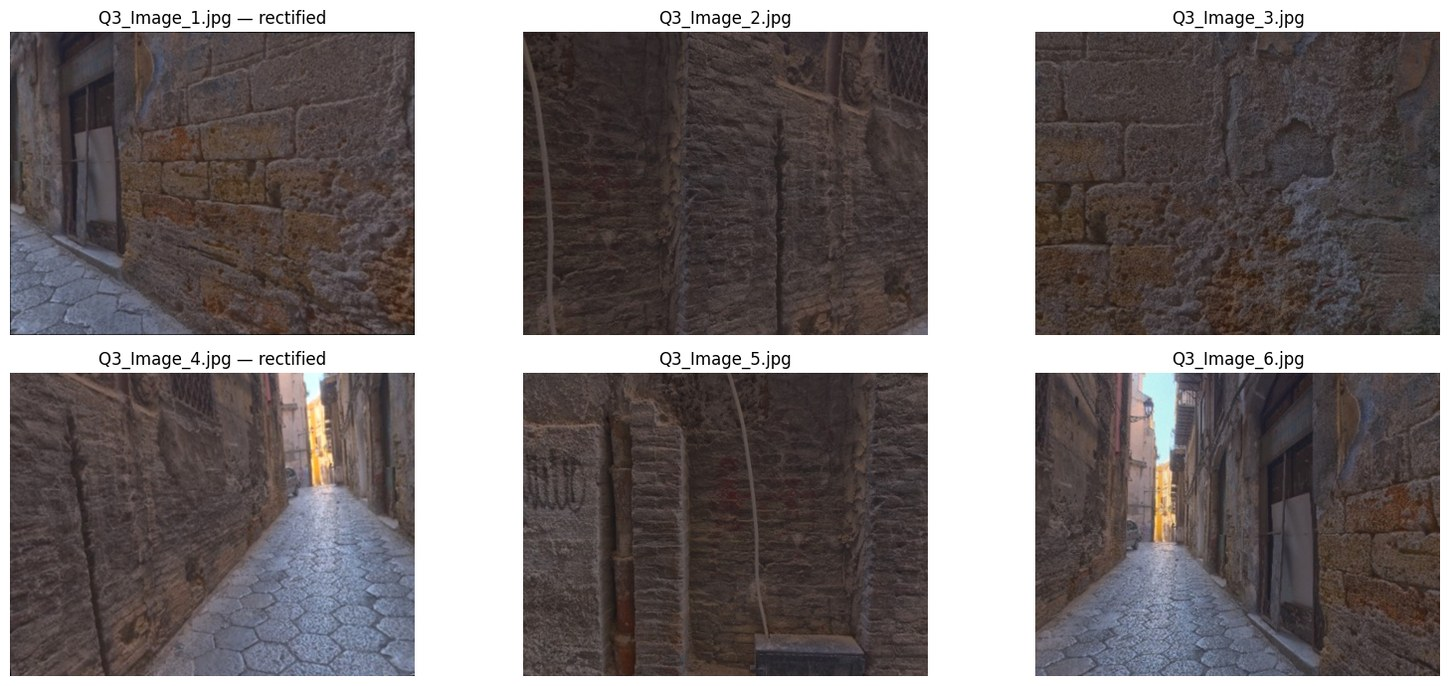

Rectified Q3_Image_1.jpg: border score=0.878, corners=[[78, 24], [610, 0], [639, 439], [17, 479]]
Rectified Q3_Image_4.jpg: border score=0.486, corners=[[0, 71], [590, 0], [639, 408], [48, 479]]
Automatically detected altered inputs: ['Q3_Image_1.jpg', 'Q3_Image_4.jpg']


In [ ]:
q3_paths = sorted(images_under(ROOT / "Q3"))
raw_imgs = [read_bgr(p) for p in q3_paths]
N = len(raw_imgs)
assert N == 6, f"Expected six views, found {N}"


# Define border scoring and perspective-rectification helpers.
def black_border_fraction(im, width=12):
    black = np.max(im, axis=2) <= 5
    border = np.zeros(black.shape, bool)
    border[:width] = border[-width:] = True
    border[:, :width] = border[:, -width:] = True
    return float(black[border].mean())


def order_quad(points):
    points = np.float32(points).reshape(4, 2)
    sums = points.sum(axis=1)
    diffs = np.diff(points, axis=1).ravel()
    return np.float32(
        [
            points[np.argmin(sums)],
            points[np.argmin(diffs)],
            points[np.argmax(sums)],
            points[np.argmax(diffs)],
        ]
    )


def rectify_visible_quad(im):
    h, w = im.shape[:2]
    visible = (np.max(im, axis=2) > 5).astype(np.uint8)
    visible = cv2.morphologyEx(visible, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
    contours, _ = cv2.findContours(visible, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    hull = cv2.convexHull(max(contours, key=cv2.contourArea))
    quad = None
    for epsilon in np.linspace(0.005, 0.08, 76):
        candidate = cv2.approxPolyDP(hull, epsilon * cv2.arcLength(hull, True), True)
        if len(candidate) == 4:
            quad = order_quad(candidate)
            break
    if quad is None:
        raise RuntimeError("Could not detect the four visible corners")
    target = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    C = cv2.getPerspectiveTransform(quad, target)
    corrected = cv2.warpPerspective(im, C, (w, h))
    mask = cv2.warpPerspective(visible, C, (w, h), flags=cv2.INTER_NEAREST)
    return corrected, mask, C, quad


# Identify and rectify the two altered views.
border_scores = np.array([black_border_fraction(im) for im in raw_imgs])
rank = np.argsort(border_scores)[::-1]
assert (
    border_scores[rank[1]] > 0.02
    and border_scores[rank[1]] > 2 * border_scores[rank[2]]
), f"Two altered inputs are not clearly identifiable: {border_scores}"
distorted = set(rank[:2].tolist())
imgs, valid_masks, corrections = [], [], []
for i, im in enumerate(raw_imgs):
    if i in distorted:
        corrected, mask, C, quad = rectify_visible_quad(im)
        print(
            f"Rectified {q3_paths[i].name}: border score={border_scores[i]:.3f}, corners={quad.round().astype(int).tolist()}"
        )
    else:
        corrected = im
        mask = np.ones(im.shape[:2], np.uint8)
        C = np.eye(3, dtype=np.float64)
    imgs.append(corrected)
    valid_masks.append(mask)
    corrections.append(C)
print(
    "Automatically detected altered inputs:",
    [q3_paths[i].name for i in sorted(distorted)],
)
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(cv2.cvtColor(imgs[i], cv2.COLOR_BGR2RGB))
    ax.set_title(q3_paths[i].name + (" — rectified" if i in distorted else ""))
    ax.axis("off")
plt.tight_layout()
plt.show()

# Match original-pixel features and build the RANSAC overlap graph.
features = [
    sift.detectAndCompute(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), None) for im in raw_imgs
]
weights = np.zeros((N, N), int)
transforms = {}
for i in range(N):
    for j in range(i + 1, N):
        ki, di = features[i]
        kj, dj = features[j]
        if di is None or dj is None:
            continue
        pairs = cv2.BFMatcher().knnMatch(di, dj, k=2)
        good = [m for m, n in pairs if m.distance < 0.75 * n.distance]
        if len(good) < 8:
            continue
        pi = np.float32([ki[m.queryIdx].pt for m in good])
        pj = np.float32([kj[m.trainIdx].pt for m in good])
        Hraw, inliers = cv2.findHomography(pi, pj, cv2.RANSAC, 3.0)
        if Hraw is None:
            continue
        count = int(inliers.sum())
        if count < 8:
            continue
        weights[i, j] = weights[j, i] = count
        H = corrections[j] @ Hraw @ np.linalg.inv(corrections[i])
        transforms[i, j] = H / H[2, 2]
        inverse = np.linalg.inv(H)
        transforms[j, i] = inverse / inverse[2, 2]
print("RANSAC inlier matrix (input order 1–6):\n", weights)

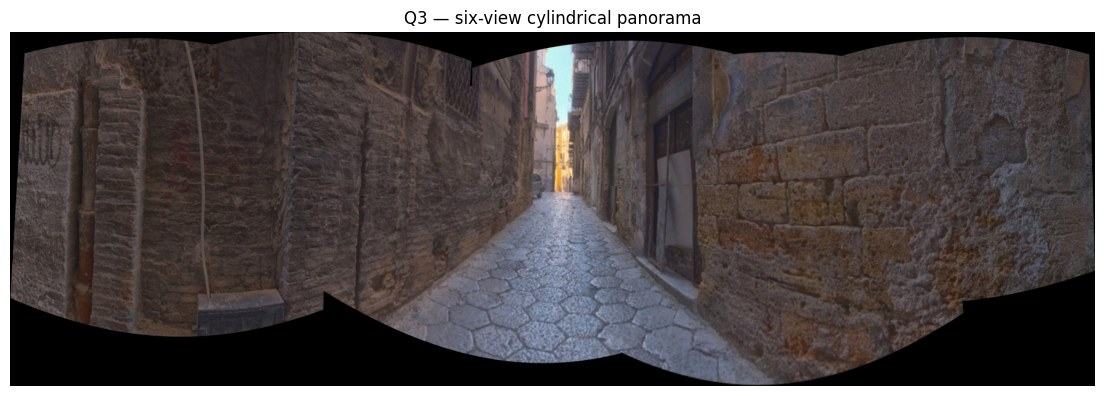

Reference: Q3_Image_6.jpg
Child -> parent, inliers: [('Q3_Image_4.jpg', 'Q3_Image_6.jpg', 493), ('Q3_Image_1.jpg', 'Q3_Image_6.jpg', 166), ('Q3_Image_3.jpg', 'Q3_Image_1.jpg', 223), ('Q3_Image_2.jpg', 'Q3_Image_4.jpg', 104), ('Q3_Image_5.jpg', 'Q3_Image_2.jpg', 65)]
Estimated focal length (pixels): 425.52
Left-to-right: ['Q3_Image_5.jpg', 'Q3_Image_2.jpg', 'Q3_Image_4.jpg', 'Q3_Image_6.jpg', 'Q3_Image_1.jpg', 'Q3_Image_3.jpg']
Cylindrical canvas: 1921 627


In [ ]:
# Step 1: Connect all six views using the strongest RANSAC-supported edges.
from scipy.optimize import least_squares

root = max((i for i in range(N) if i not in distorted), key=lambda i: weights[i].sum())
placed = {root: np.eye(3)}
chosen = []
while len(placed) < N:
    candidates = [
        (int(weights[parent, child]), parent, child)
        for parent in placed
        for child in range(N)
        if child not in placed and (child, parent) in transforms
    ]
    assert candidates, "The overlap graph is disconnected"
    count, parent, child = max(candidates)
    placed[child] = placed[parent] @ transforms[child, parent]
    placed[child] /= placed[child][2, 2]
    chosen.append((q3_paths[child].name, q3_paths[parent].name, count))
print("Reference:", q3_paths[root].name)
print("Child -> parent, inliers:", chosen)

# Step 2: Estimate a shared focal length from undistorted overlapping pairs.
# For a rotating camera, K^-1 H K should approximately be a rotation.
h0, w0 = imgs[root].shape[:2]
cx, cy = w0 / 2, h0 / 2
center = np.array([[1.0, 0, -cx], [0, 1, -cy], [0, 0, 1]])
calibration_H = [
    center @ transforms[i, j] @ np.linalg.inv(center)
    for i, j in transforms
    if i < j and i not in distorted and j not in distorted
]
assert calibration_H, "No undistorted overlapping pair for focal estimation"


def rotation_residual(logf):
    K0 = np.diag([np.exp(logf[0]), np.exp(logf[0]), 1.0])
    residual = []
    for Hpair in calibration_H:
        R = np.linalg.inv(K0) @ Hpair @ K0
        R /= np.cbrt(np.linalg.det(R))
        residual.extend((R.T @ R - np.eye(3)).ravel())
    return residual


fit = least_squares(
    rotation_residual, [np.log(w0)], bounds=([np.log(w0 * 0.2)], [np.log(w0 * 4)])
)
focal = float(np.exp(fit.x[0]))
K = np.array([[focal, 0, cx], [0, focal, cy], [0, 0, 1.0]])
print("Estimated focal length (pixels):", round(focal, 2))

# Step 3: Map homogeneous rays to a cylinder, avoiding the planar horizon.
# Keeping ray signs matters: dividing by depth first can reverse extreme views.
rays = {i: np.linalg.inv(K) @ placed[i] for i in range(N)}
boundaries, angles = [], []
for i, A in rays.items():
    if np.linalg.det(A) < 0:
        A = rays[i] = -A
    h, w = imgs[i].shape[:2]
    x, y = np.linspace(0, w - 1, 100), np.linspace(0, h - 1, 100)
    perimeter = np.vstack(
        [
            np.c_[x, x * 0],
            np.c_[x, x * 0 + h - 1],
            np.c_[y * 0, y],
            np.c_[y * 0 + w - 1, y],
        ]
    )
    q = np.c_[perimeter, np.ones(len(perimeter))] @ A.T
    boundaries.append(
        focal
        * np.c_[np.arctan2(q[:, 0], q[:, 2]), q[:, 1] / np.hypot(q[:, 0], q[:, 2])]
    )
    middle = A @ np.array([w / 2, h / 2, 1.0])
    angles.append(np.arctan2(middle[0], middle[2]))
lo = np.floor(np.vstack(boundaries).min(axis=0)).astype(int)
hi = np.ceil(np.vstack(boundaries).max(axis=0)).astype(int)
W, H = (hi - lo + 1).tolist()
assert 0 < W < 12000 and 0 < H < 6000, "Implausible canvas"
print("Left-to-right:", [q3_paths[i].name for i in np.argsort(angles)])
print("Cylindrical canvas:", W, H)
x, y = np.meshgrid((np.arange(W) + lo[0]) / focal, (np.arange(H) + lo[1]) / focal)
world = np.stack([np.sin(x), y, np.cos(x)], axis=-1)

# Step 4: Inverse-warp all corrected views and feather their valid pixels.
acc = np.zeros((H, W, 3), np.float32)
weightsum = np.zeros((H, W), np.float32)
for i, img in enumerate(imgs):
    p = world @ np.linalg.inv(rays[i]).T
    depth = p[:, :, 2]
    safe_depth = np.where(np.abs(depth) > 1e-8, depth, 1e-8)
    mx = (p[:, :, 0] / safe_depth).astype(np.float32)
    my = (p[:, :, 1] / safe_depth).astype(np.float32)
    warped = cv2.remap(img, mx, my, cv2.INTER_LINEAR)
    valid = valid_masks[i].astype(np.uint8)
    distance = cv2.distanceTransform(np.pad(valid, 1), cv2.DIST_L2, 3)[1:-1, 1:-1]
    soft = np.minimum(distance, 40).astype(np.float32) * valid
    feather = cv2.remap(soft, mx, my, cv2.INTER_LINEAR) * (depth > 0)
    assert np.any(feather > 0), f"View {i + 1} contributes no pixels"
    acc += warped.astype(np.float32) * feather[:, :, None]
    weightsum += feather
panorama = np.uint8(np.clip(acc / np.maximum(weightsum[:, :, None], 1e-6), 0, 255))
ys, xs = np.where(weightsum > 0)
panorama = panorama[ys.min() : ys.max() + 1, xs.min() : xs.max() + 1]
show("Q3 — six-view cylindrical panorama", panorama, figsize=(14, 5))
result_dir = ROOT / "results"
result_dir.mkdir(exist_ok=True)
assert cv2.imwrite(str(result_dir / "q3_panorama.png"), panorama)
print("Saved:", result_dir / "q3_panorama.png")

### Q3 — Panoramic image stitching

- **Rectify:** Detect the two altered views from their black borders and map their visible quadrilaterals to rectangles. Display all six corrected views.
- **Match:** Extract SIFT features from the original images to avoid resampling loss, filter descriptor matches, and estimate pairwise homographies with RANSAC. Convert them to corrected-image coordinates using `C_j H_ij C_i^{-1}`.
- **Connect:** Build a maximum-overlap tree from inlier counts and compose transforms into an undistorted reference frame. The view order is computed, not supplied by filename order.
- **Project:** Estimate a shared focal length from undistorted overlapping views under an approximate rotating-camera model. Map homogeneous rays onto a cylinder, preserving their signs, and compute the canvas bounds and offset from sampled image borders.
- **Blend:** Inverse-warp all six corrected views and feather-blend using distance-to-boundary weights. Save `results/q3_panorama.png`. No high-level stitching function or manually chosen transforms are used.
- **Result and limitations:** Cylindrical projection avoids the extreme side stretching of the previous single-plane panorama. It retains all six views; irregular outer blank regions are left visible to preserve coverage. Small seams, parallax, and calibration/rectification errors can remain. The focal estimate is approximate, not a measured camera calibration; hidden-ground-truth accuracy is unknown.

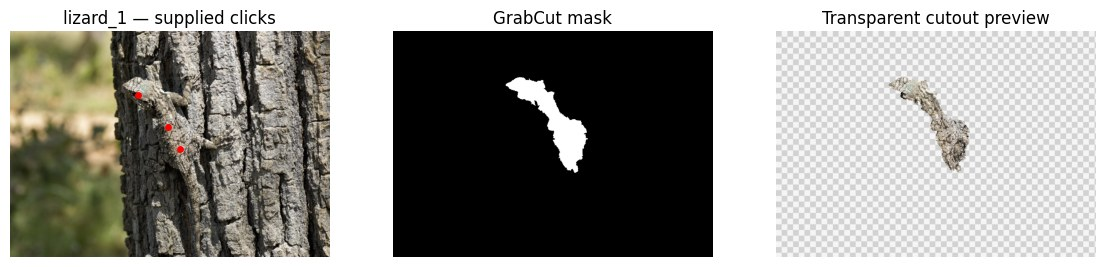

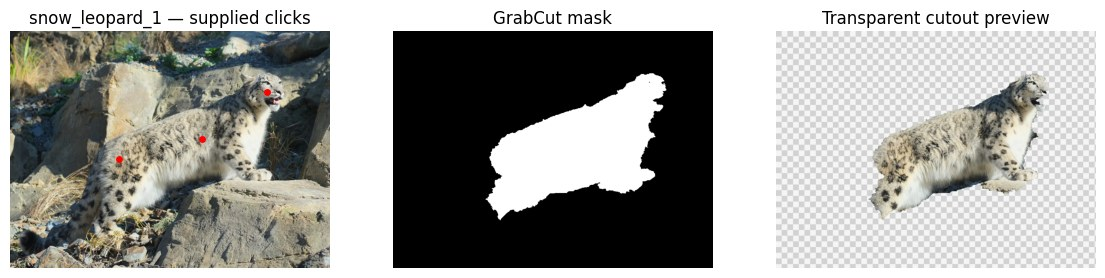

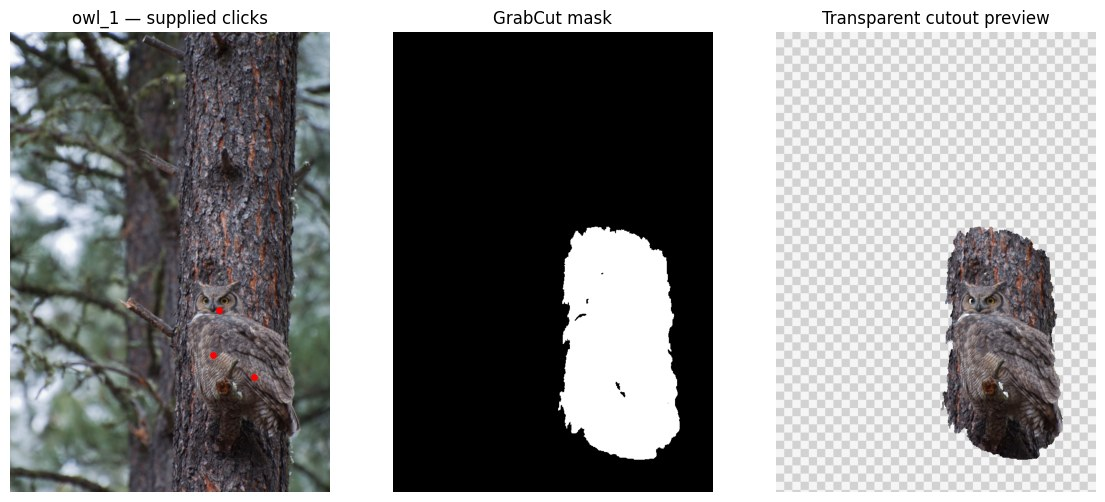

In [ ]:
# Step 1: Load the supplied foreground clicks.
click_data = json.loads((ROOT / "Q4" / "clicks.json").read_text())
out_dir = ROOT / "results" / "q4_grabcut"
out_dir.mkdir(parents=True, exist_ok=True)
saved = []
cv2.setRNGSeed(0)
for filename, instances in click_data.items():
    original = read_bgr(ROOT / "Q4" / filename)
    oh, ow = original.shape[:2]
    scale = min(1.0, 900 / max(oh, ow))
    img = cv2.resize(original, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    h, w = img.shape[:2]
    for name, info in instances.items():
        original_pts = np.rint(np.asarray(info["clicks"])).astype(np.int32)
        assert ((original_pts >= 0) & (original_pts < [ow, oh])).all()
        pts = np.rint(original_pts * [w / ow, h / oh]).astype(np.int32)
        pts = np.clip(pts, [0, 0], [w - 1, h - 1])

        # Step 2: Initialize GrabCut with heuristic bands around the click path.
        radius_fraction = {"lizard_1": 0.065, "snow_leopard_1": 0.15, "owl_1": 0.13}
        r = max(12, int(radius_fraction.get(name, 0.1) * min(h, w)))
        inner = np.zeros((h, w), np.uint8)
        outer = np.zeros((h, w), np.uint8)
        path = pts.reshape(-1, 1, 2)
        cv2.polylines(inner, [path], False, 1, 2 * r)
        cv2.polylines(outer, [path], False, 1, 4 * r)
        labels = np.full((h, w), cv2.GC_BGD, np.uint8)
        labels[outer > 0] = cv2.GC_PR_BGD
        labels[inner > 0] = cv2.GC_PR_FGD
        for x, y in pts:
            cv2.circle(labels, (int(x), int(y)), max(6, r // 4), cv2.GC_FGD, -1)

        # Step 3: Fit color mixtures, run graph cuts, and retain clicked components.
        bg = np.zeros((1, 65), np.float64)
        fg = np.zeros((1, 65), np.float64)
        cv2.grabCut(img, labels, None, bg, fg, 5, cv2.GC_INIT_WITH_MASK)
        binary = np.isin(labels, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype(np.uint8)
        _, components = cv2.connectedComponents(binary, connectivity=8)
        selected = np.unique(components[pts[:, 1], pts[:, 0]])
        selected = selected[selected > 0]
        binary = np.isin(components, selected).astype(np.uint8)
        assert binary[pts[:, 1], pts[:, 0]].all(), "Foreground seed lost"

        # Step 4: Export original-resolution RGBA and validate the saved file.
        alpha = cv2.resize(binary, (ow, oh), interpolation=cv2.INTER_NEAREST) * 255
        rgba = cv2.cvtColor(original, cv2.COLOR_BGR2BGRA)
        rgba[:, :, 3] = alpha
        target = out_dir / (name + ".png")
        assert cv2.imwrite(str(target), rgba)
        checked = cv2.imread(str(target), cv2.IMREAD_UNCHANGED)
        assert checked.shape == (oh, ow, 4)
        assert np.array_equal(checked[:, :, :3], original)
        assert np.array_equal(checked[:, :, 3], alpha)
        assert (checked[original_pts[:, 1], original_pts[:, 0], 3] == 255).all()
        assert (alpha == 0).any() and (alpha == 255).any()
        saved.append(target)
        print(
            f"{name}: {len(pts)}/{len(pts)} clicks retained; foreground={binary.mean():.3f}"
        )
        print("Saved:", target)

        # Step 5: Display clicks, mask, and a checkerboard transparency preview.
        rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        yy, xx = np.indices((h, w))
        checker = (210 + 35 * ((xx // 16 + yy // 16) % 2)).astype(np.uint8)
        preview = np.where(binary[:, :, None] > 0, rgb, checker[:, :, None])
        fig, axes = plt.subplots(1, 3, figsize=(14, 6))
        axes[0].imshow(rgb)
        axes[0].scatter(pts[:, 0], pts[:, 1], c="red", s=15)
        axes[0].set_title(name + " — supplied clicks")
        axes[1].imshow(binary, cmap="gray", vmin=0, vmax=1)
        axes[1].set_title("GrabCut mask")
        axes[2].imshow(preview)
        axes[2].set_title("Transparent cutout preview")
        for ax in axes:
            ax.axis("off")
        plt.show()
assert len(saved) == sum(len(instances) for instances in click_data.values())
print("Validated GrabCut RGBA PNGs:", len(saved))

### Q4 — Click-seeded GrabCut segmentation

- **Initialize:** Resize to a maximum side of 900 pixels and scale the supplied clicks. Use heuristic click-path bands for probable foreground/background, definite background outside the outer band, and definite foreground around the clicks. No additional manual clicks or outlines are supplied.
- **Segment:** Run five GrabCut iterations using color mixture models and graph cuts, then keep foreground components containing supplied clicks. No pretrained model or deep learning is used.
- **Controlled tests:** Compare mild bilateral filtering (d=5, sigmaColor=25, sigmaSpace=5) with the original image using identical seeds, five iterations, and a reset random seed. Separately expand only the uncertain background region by dilating the outer band by radius r. Neither trial showed a clear overall visual improvement: filtering added background near the snow leopard; background relaxation included more rock and tree trunk. Retain the original method without either change. These are visual comparisons, not ground-truth accuracy measurements.
- **Export and verify:** Save original-resolution RGBA PNGs to results/q4_grabcut/, preserving original RGB values. Re-read each file and check dimensions, alpha, and inclusion of every supplied click. Earlier SAM files in results/q4/ are not final outputs.
- **Limitations:** Camouflage leaves bark/trunk contamination, and the band constraint can exclude limbs or tails. More foreground pixels do not necessarily mean a better mask.
- **Additional controlled tests:** Test 2-pixel definite-foreground seeds; color-connected initialization within the unchanged outer band (OpenCV Lab distance < 35 from a supplied click); Lab input; 10 rather than 5 iterations; and coarse-to-fine refinement at a maximum side of 1500 pixels with an uncertain boundary band. Each variant is compared separately with a fixed-seed baseline on all three images.
- **Observed outcome:** Smaller seeds increased snow-leopard undersegmentation. Color initialization fragmented the snow leopard and removed part of the owl. Lab, extra iterations, and higher-resolution refinement changed local boundaries without clearly improving the overall cutouts. Retain the original simple method. This conclusion applies to these tested settings, not every possible parameter choice.

## AI Use Disclosure

### Tool and scope of assistance

- I used OpenAI Codex as an assistant for Questions 1–4. I directed the work through questions about the assignment, possible methods, intermediate results, and visible errors. Codex helped explain methods, propose and revise code, interpret outputs, and draft notebook descriptions.
- Codex's assistance included substantial implementation code and parameter suggestions. It was not limited to proofreading, but I did not treat its outputs as automatically correct.

### My participation and verification

- I chose which methods to test, reviewed results in Google Colab, questioned outputs that looked wrong, and requested comparisons with earlier versions. I asked for concise working methods and explanations of the processing steps.
- I initially approved testing and retaining SAM after a TA reply appeared to permit learned methods. After a further reply left the restriction ambiguous, I requested a return to classical GrabCut. SAM was part of the development process but is not used by the final Q4 code.
- I reran an earlier complete notebook. Codex assisted with subsequent execution and output checks. The final code checks that all six views contribute to Q3 and that Q4 exports original-resolution RGBA PNGs with unchanged RGB values and all supplied foreground clicks retained.
- These checks verify execution and output properties, not accuracy against hidden ground truth. I remain responsible for reviewing the final saved outputs and understanding the code.

### Assistance by question

- **Q1:** I asked Codex to compare boundary-detection methods and test color-contrast enhancement, Canny edges, and line fitting. I reviewed the intermediate images and boundary lines.
- **Q2:** I asked Codex to compare ways to locate the cover under perspective distortion. It helped implement SIFT matching, RANSAC homography estimation, and replacement-image warping; I reviewed the projected corners and result.
- **Q3:** I questioned misalignment and severe stretching and asked for revisions. Codex retained feature matching and explicit transform composition, then tested cylindrical projection to reduce the excessive stretching of a planar panorama. All six views are included without a high-level stitcher; some seams and irregular outer blank regions remain.
- **Q4:** Codex helped implement click-seeded GrabCut and later test SAM. I ultimately requested the earlier GrabCut method to avoid the ambiguity over deep-learning permission. The final method uses heuristic click-path bands, foreground/background color mixtures, graph cuts, and click-containing connected components. It saves verified transparent PNGs to results/q4_grabcut/. Some bark/trunk contamination and missing fine structures remain; the change was made for method compliance, not because GrabCut outperformed SAM.

- **Further Q4 tests:** At my request, Codex compared mild bilateral filtering and, separately, a wider uncertain background region with the baseline. Visual inspection showed no clear overall improvement and more background leakage in some images, so the original GrabCut implementation and PNGs were retained. These tests did not use extra manual annotations or ground-truth masks.

### Question chain

- This is a condensed, polished summary of my prompts, not a verbatim chronological transcript. Earlier requests to retain SAM describe an intermediate decision, superseded by the final request to restore GrabCut. The final notebook contains only the selected implementation.

1. Explain Q1 and compare common ways to detect the two runway boundaries.
2. Try color-contrast enhancement, Canny edge detection, and line fitting. Show the intermediate images and final two lines.
3. Explain Q2 and compare ways to locate the cover under perspective distortion.
4. Try SIFT matching, a RANSAC homography, and perspective warping. Show the detected corners and replacement result.
5. Explain Q3, its required outputs, and the main approaches to correcting and stitching the images.
6. Identify the distorted views and rectify them. Show all six views before stitching.
7. Test feature matching between overlapping pairs. Which pairs are reliable, and should features be extracted before or after rectification?
8. Use the reliable matches to build a six-view panorama. Show the pairwise connections and final image.
9. The alignment looks off. Is the problem in matching, homography estimation, transform composition, or blending? Explain what the result suggests.
10. Try the most promising adjustment first and compare it with the previous panorama. Keep the better version.
11. Explain Q4 and compare methods that can use the supplied clicks to segment each object.
12. Try a click-seeded segmentation method on one image. Show the seed regions, mask, and transparent preview.
13. What explains the visible segmentation errors? Check the seed design, similar foreground and background colors, and connected components.
14. Change one part of the method and compare the new mask with the previous one. Keep the better version.
15. Apply that method to the other images. Review each mask separately and make image-specific adjustments only where needed.
16. Check Q1–Q4 against the assignment requirements. Separate missing requirements from visual imperfections.
17. Keep only the best working version of each method. Add short bullet-point Markdown explanations and # Step comments in code cells, then rerun the notebook.
18. The Q3 panorama is still misaligned, and the images are heavily stretched. What methods could address these problems?
19. Let's try cylindrical projection and compare it with the previous panorama.
20. Here is the TA's new clarification. With the classical-CV restriction lifted, what methods could we use for Q4?
21. Test SAM with the supplied clicks and show how its results compare with the earlier click-seeded GrabCut results.
22. Keep SAM as the final Q4 method.
23. Finalize the notebook and check it against the assignment requirements. Add an AI Use Disclosure section at the end, following the same structure as Project 1.
24. Return Q4 to GrabCut to avoid the ambiguity over whether deep-learning methods are allowed.

25. Test mild bilateral preprocessing and relaxed background constraints separately, compare the results, and keep the better version.

### Responsibility and limitations

- Codex assisted with analysis, implementation, and writing; I directed the questions and method choices and questioned earlier results. The outputs have not been validated against ground-truth annotations. Some method parameters, including GrabCut initialization widths, were chosen heuristically.
- The final Q4 method is classical GrabCut and does not rely on an interpretation that deep learning is permitted. I remain responsible for the submitted code, results, and explanations.

- I also requested further single-change GrabCut experiments. Codex tested smaller foreground seeds, color-connected initialization, Lab input, more iterations, and higher-resolution boundary refinement on all three images. After visual comparison, the original implementation was retained because the tested variants did not clearly improve the overall results. No ground-truth accuracy score was available.